# 04 — Interprétation métier des partitions CAH (ACM 3)

**Objectif :** analyser les partitions à 4, 5 et 6 groupes sur les **mêmes dix variables actives et 42 modalités** que l’ACM définitive. La CAH est déjà calculée : ce notebook n'ajuste ni l’ACM, ni Ward.

**Parcours :** contrôle des données → effectifs → projection factorielle → profils → fiches métier → scissions → décision provisoire.

> Les étiquettes G1, G2… sont propres à chaque partition. Les résultats décrivent les clients de l'essai CAH chargé, et non automatiquement toute la population ACM. La validation de stabilité sera réalisée séparément.

## 1. Chargement et contrôle des correspondances

Les partitions sont rapprochées des lignes brutes par identifiant ou indice source. Les positions de l’échantillon sont également contrôlées dans `correspondance_clients_acm.csv`. Un indice source n'est valide que si le CSV brut et son ordre n'ont pas changé.

In [15]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
from IPython.display import display, Markdown

RACINE = Path.cwd().resolve()
if RACINE.name == "notebooks":
    RACINE = RACINE.parent
if str(RACINE) not in sys.path:
    sys.path.insert(0, str(RACINE))

from src.interpretation import (
    charger_partitions_et_donnees,
    preparer_variables_acm_finales,
    tailles_partitions,
    profils_modalites,
    caracteristiques_principales,
    profils_quantitatifs,
    transitions_groupes,
    differences_enfants,
)
from src.visualisation_factorielle import (
    charger_coordonnees_partitions, afficher_partitions_factorielles,
)
from src.synthese_metier import (
    fiches_groupes, resumer_scissions, bilan_comparatif,
)
from src.visualisation_interpretation import (
    afficher_tailles_groupes,
    afficher_carte_ecarts,
    afficher_transitions,
)

MODE = "essai"  # "complet" uniquement si la CAH complète a été exécutée
NOMBRE_AXES_CAH = 4
K_CENTRAL = 5
VALEURS_K = [K_CENTRAL - 1, K_CENTRAL, K_CENTRAL + 1]

partitions, descriptifs, parametres_cah = charger_partitions_et_donnees(
    RACINE, mode=MODE, nombre_axes=NOMBRE_AXES_CAH
)
if sorted(parametres_cah["valeurs_k"]) != VALEURS_K:
    raise ValueError("Les valeurs de k ne correspondent pas aux partitions exportées.")
if int(parametres_cah["k_central"]) != K_CENTRAL:
    raise ValueError("Le nombre central de groupes ne correspond pas à la CAH.")
print(f"Mode d'analyse : {MODE}")
print(f"Individus appariés : {len(partitions):,}")
print(f"Nombre d'axes : {NOMBRE_AXES_CAH}")
print(f"Partitions disponibles : {VALEURS_K}")
display(partitions.head())
TAILLE_ATTENDUE = 20000  # Expérience courante ; changer si une autre expérience est chargée
if len(partitions) != TAILLE_ATTENDUE:
    raise ValueError(
        f"Expérience inattendue : {len(partitions)} individus au lieu de {TAILLE_ATTENDUE}. "
        "Vérifier les exports du notebook 03 et ajuster TAILLE_ATTENDUE si nécessaire."
    )


Mode d'analyse : essai
Individus appariés : 20,000
Nombre d'axes : 4
Partitions disponibles : [4, 5, 6]


,position_echantillon,id_anonyme,groupe_k4,groupe_k5,groupe_k6
0,0,732b17b69563608c305596b612987b34aa6cb78b95aa86...,1,1,1
1,18,278075c7f72b348942fe0d09a4043004605025b79f184c...,2,2,2
2,19,1649c0317a7e8d5dbe3fdffaa36970c0682e57b098502b...,3,3,3
3,23,869c7250a91966fc38a7dcb2773e214e68fa2b7263c676...,2,2,2
4,24,6de6c7589016a020bf0e68bd1e31753ee7fb899262e0f0...,2,4,4


## 2. Taille des groupes

Visualiser les effectifs, la proportion de chaque groupe et les éventuels déséquilibres. Une petite taille n’est pas en elle-même un motif de rejet, mais demande une interprétation prudente.

,k,Groupe,Effectif,Part (%)
0,4,1,5134,25.67
1,4,2,8212,41.06
2,4,3,2201,11.00
3,4,4,4453,22.26
4,5,1,5134,25.67
5,5,2,4152,20.76
6,5,3,2201,11.00
7,5,4,4060,20.30
8,5,5,4453,22.26
9,6,1,5134,25.67


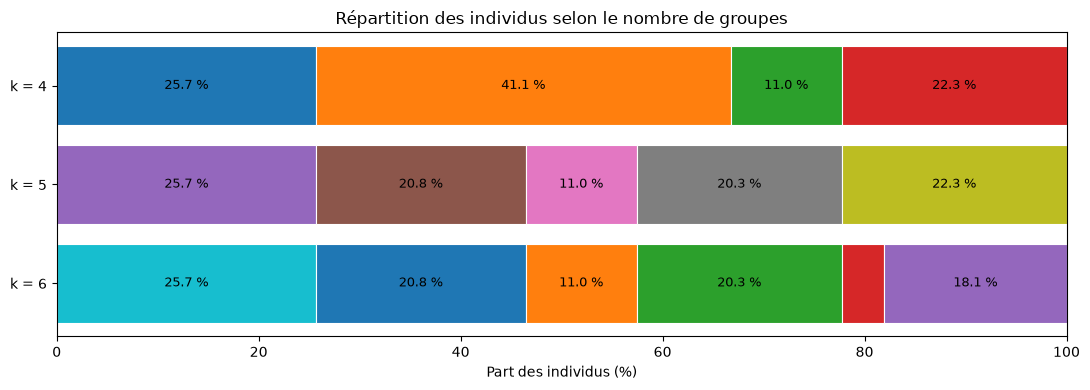

In [2]:
tailles = tailles_partitions(partitions, VALEURS_K)
display(tailles.round(2))
afficher_tailles_groupes(tailles)

## 3. Position des groupes dans le plan factoriel de l'ACM

Chaque point représente un client, coloré selon sa partition CAH. Les croix indiquent les **centres moyens calculés sur tous les individus**. Pour éviter la surcharge, seuls quelques milliers de points sont affichés, avec un **échantillonnage commun** aux trois partitions.

La CAH utilise quatre axes : les projections **(1, 2)** et **(3, 4)** sont donc complémentaires. Les couleurs et noms G1… ne suffisent pas pour établir une correspondance entre valeurs de *k*. Aucune ellipse ni frontière de décision n'est supposée.

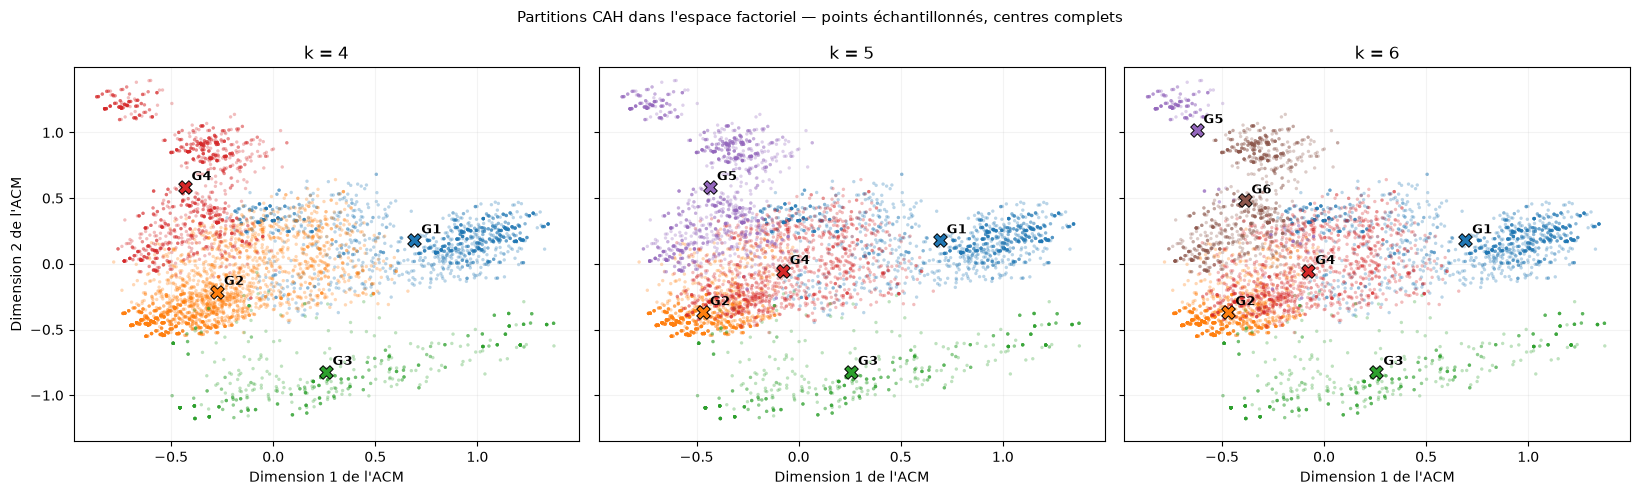

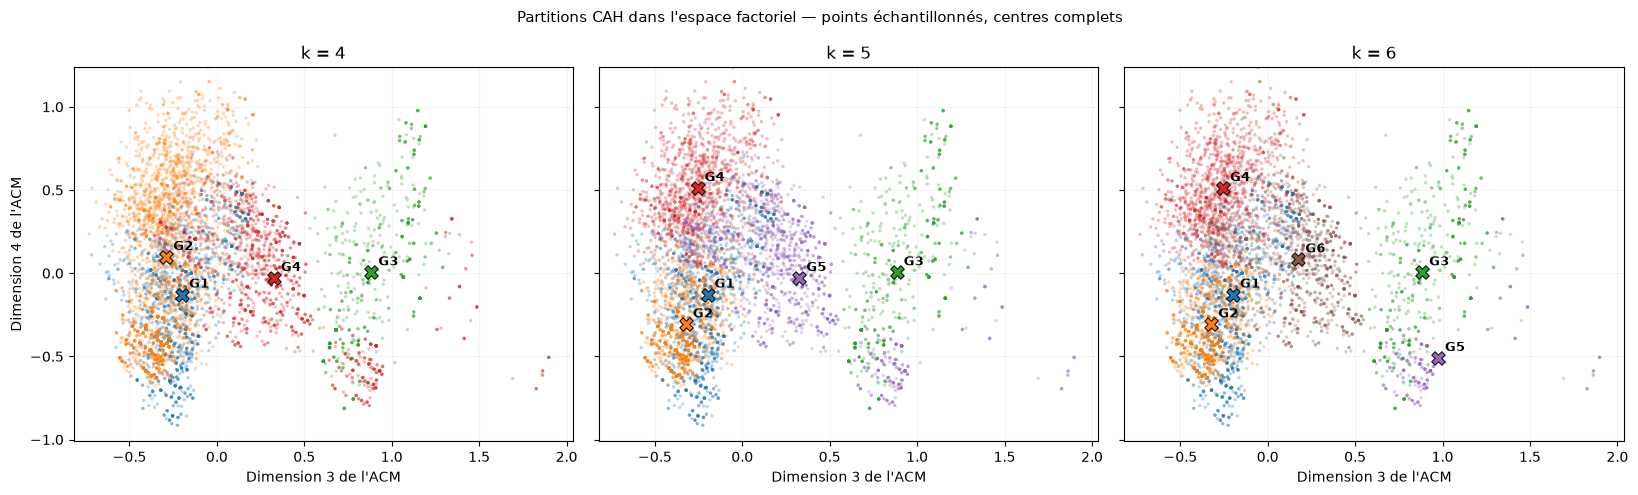

In [3]:
# Association stricte des coordonnées de l'ACM aux étiquettes de CAH
coordonnees_cah = charger_coordonnees_partitions(
    RACINE, partitions, nombre_axes=NOMBRE_AXES_CAH
)
assert len(coordonnees_cah) == len(partitions)
REPERTOIRE_FIGURES = RACINE / "resultats" / "cah" / "interpretation" / "figures"
afficher_partitions_factorielles(
    coordonnees_cah, partitions, VALEURS_K, axes=(1, 2),
    maximum_points=6000, graine=42,
    chemin_sortie=REPERTOIRE_FIGURES / "partitions_axes_1_2.png",
)
afficher_partitions_factorielles(
    coordonnees_cah, partitions, VALEURS_K, axes=(3, 4),
    maximum_points=6000, graine=42,
    chemin_sortie=REPERTOIRE_FIGURES / "partitions_axes_3_4.png",
)

## 4. Reconstruction des variables actives de l’ACM 3

La préparation est **identique à celle de `02_acm.ipynb`** : recodifications de `config/regroupements.yaml`, exclusion préalable des paiements `Others`, puis application de la seule fusion finale `avg_songs_sessions_rec`.

Les noms des dix variables actives, les 42 modalités de référence et la fusion finale sont contrôlés dans `modeles/acm_final_metadonnees.json`. Aucune variable brute, variable supplémentaire ou variable numérique non active n’est intégrée aux profils. Les modalités absentes de l'essai CAH restent possibles dans l'échantillon complet de l'ACM.

In [4]:
# Reconstitution et vérification stricte des variables actives de l’ACM 3
# Les données sont déjà ordonnées comme les étiquettes des partitions CAH.
donnees_acm, metadonnees_acm = preparer_variables_acm_finales(descriptifs, RACINE)
VARIABLES_QUALITATIVES = list(metadonnees_acm["variables_actives"])
VARIABLES_QUANTITATIVES = []

assert len(donnees_acm) == len(partitions)
assert donnees_acm.columns.tolist() == VARIABLES_QUALITATIVES
assert len(VARIABLES_QUALITATIVES) == 10
assert len(metadonnees_acm["modalites_actives"]) == 42

print("Itération ACM :", metadonnees_acm["iteration"])
print("Variables actives de l'ACM 3 :", VARIABLES_QUALITATIVES)
print("Nombre de variables :", len(VARIABLES_QUALITATIVES))
print("Nombre de modalités de référence :", len(metadonnees_acm["modalites_actives"]))
print("Fusions finales :", metadonnees_acm["regroupements_acm_finaux"])
display(donnees_acm.head())

Itération ACM : 3
Variables actives de l'ACM 3 : ['type_client', 'ratio_fidelite_tr', 'utilise_remote', 'contactable', 'anciennete_client_rec', 'anciennete_abonnement_rec', 'methode_paiement_rec', 'valeur_12M_rec', 'avg_sessions_actifs_rec', 'avg_songs_sessions_rec']
Nombre de variables : 10
Nombre de modalités de référence : 42
Fusions finales : {'avg_songs_sessions_rec': {'03_10_et_plus': ['03_Eleve_10_a_20', '04_Tres_eleve_20_et_plus']}}


,type_client,ratio_fidelite_tr,utilise_remote,contactable,anciennete_client_rec,anciennete_abonnement_rec,methode_paiement_rec,valeur_12M_rec,avg_sessions_actifs_rec,avg_songs_sessions_rec
0,nouveau,05_90_et_plus,non,non,02_6_a_12_mois,03_6_a_12_mois,web_et_direct,04_50_a_90,01_Faible_1_a_2,03_10_et_plus
1,churn,01_moins_30,non,non,03_1_a_2_ans,03_6_a_12_mois,web_et_direct,02_15_a_30,03_Eleve_4_a_8,01_Faible_1_a_5
2,churn,02_30a50,non,non,01_Moins_de_6_mois,02_3_a_5_mois,web_et_direct,02_15_a_30,00_Inactif,00_Inactif
3,churn,01_moins_30,non,non,05_Plus_de_4_ans,02_3_a_5_mois,telephone,01_Moins_de_15,01_Faible_1_a_2,03_10_et_plus
4,reactivated,04_70a90,non,oui,02_6_a_12_mois,01_Moins_de_3_mois,telephone,03_30_a_50,03_Eleve_4_a_8,01_Faible_1_a_5


In [5]:
# Diagnostic des modalités recodées dans la sous-population CAH
diagnostic_acm = pd.DataFrame({
    "Variable": VARIABLES_QUALITATIVES,
    "Nombre de modalités observées (CAH)": [
        donnees_acm[variable].nunique(dropna=True) for variable in VARIABLES_QUALITATIVES
    ],
    "Nombre de modalités de référence (ACM)": [
        sum(modalite.startswith(f"{variable}__") for modalite in metadonnees_acm["modalites_actives"])
        for variable in VARIABLES_QUALITATIVES
    ],
    "Valeurs manquantes": [
        int(donnees_acm[variable].isna().sum()) for variable in VARIABLES_QUALITATIVES
    ],
})
display(diagnostic_acm)
print("Variables descriptives utilisées : les 10 variables actives de l'ACM 3, sans ajout.")

,Variable,Nombre de modalités observées (CAH),Nombre de modalités de référence (ACM),Valeurs manquantes
0,type_client,4,4,0
1,ratio_fidelite_tr,6,6,0
2,utilise_remote,2,2,0
3,contactable,2,2,0
4,anciennete_client_rec,5,5,0
5,anciennete_abonnement_rec,5,5,0
6,methode_paiement_rec,4,4,0
7,valeur_12M_rec,5,5,0
8,avg_sessions_actifs_rec,5,5,0
9,avg_songs_sessions_rec,4,4,0


Variables descriptives utilisées : les 10 variables actives de l'ACM 3, sans ajout.


### Contrôle de la cohérence des modalités

Le tableau vérifie que l'interprétation repose bien sur les variables de l'ACM 3. **Aucune variable supplémentaire** n'est introduite. Les profils seront comparés uniquement à la distribution globale des clients de l'essai CAH.

## 5. Profils des partitions

Pour chaque modalité **recodée de l’ACM 3**, la fréquence dans un cluster est comparée à sa fréquence parmi les **individus de la CAH chargée**. Une surreprésentation descriptive ne constitue pas un test de significativité.

### Lecture des cartes de chaleur

Chaque **ligne** correspond à une modalité d’une des dix variables actives de l’ACM 3, et chaque **colonne** à un groupe (G1, G2, etc.). Les codes G1 à G6 sont les identifiants des groupes **dans la partition affichée** : ils ne correspondent pas forcément au même profil pour des valeurs de *k* différentes.

La couleur représente l’écart en **points de pourcentage** entre la fréquence de la modalité dans le groupe et sa fréquence dans **l’ensemble des individus étudiés** : **rouge = surreprésentation**, **bleu = sous-représentation**, **blanc = fréquence proche de la référence**. Par exemple, +30 signifie 30 points de plus, et non une hausse relative de 30 %.

Les cartes montrent les **18 modalités dont l’écart absolu maximal est le plus important** parmi les groupes de la partition. Elles ne montrent donc pas l’ensemble des 42 modalités de l’ACM. Les tableaux et les CSV conservent les profils détaillés.



=== k = 4 : modalités caractéristiques ===


,Groupe,Variable,Modalité,Effectif modalité groupe,Part groupe (%),Part population (%),Écart (points)
0,1,type_client,retained,3307,64.41,18.80,45.61
1,1,ratio_fidelite_tr,05_90_et_plus,3987,77.66,36.10,41.55
2,1,valeur_12M_rec,04_50_a_90,3321,64.69,25.01,39.67
3,1,anciennete_abonnement_rec,05_Plus_de_2_ans,1952,38.02,11.86,26.16
4,1,valeur_12M_rec,05_Plus_de_90,1551,30.21,9.11,21.10
5,1,anciennete_client_rec,05_Plus_de_4_ans,1534,29.88,13.86,16.02
6,1,anciennete_abonnement_rec,04_1_a_2_ans,1486,28.94,13.33,15.61
7,1,anciennete_client_rec,04_2_a_4_ans,1566,30.50,18.27,12.23
8,2,anciennete_abonnement_rec,03_6_a_12_mois,5371,65.40,38.87,26.53
9,2,type_client,churn,6308,76.81,50.72,26.09


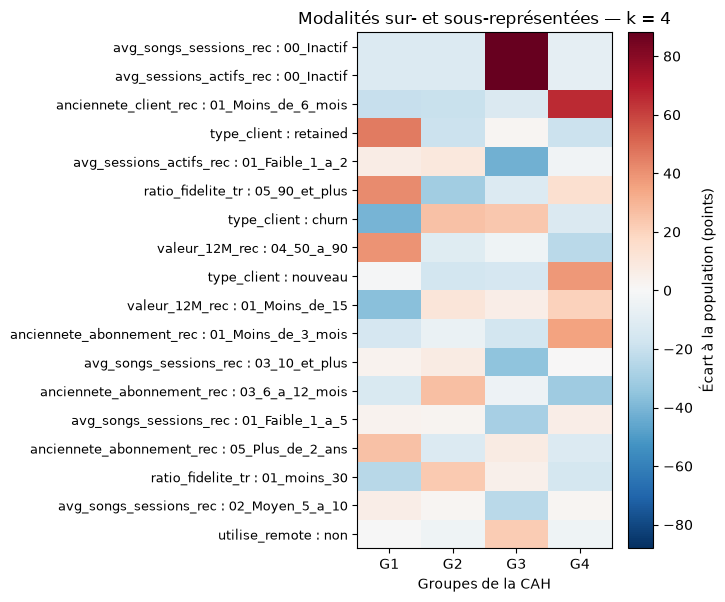


=== k = 5 : modalités caractéristiques ===


,Groupe,Variable,Modalité,Effectif modalité groupe,Part groupe (%),Part population (%),Écart (points)
0,1,type_client,retained,3307,64.41,18.80,45.61
1,1,ratio_fidelite_tr,05_90_et_plus,3987,77.66,36.10,41.55
2,1,valeur_12M_rec,04_50_a_90,3321,64.69,25.01,39.67
3,1,anciennete_abonnement_rec,05_Plus_de_2_ans,1952,38.02,11.86,26.16
4,1,valeur_12M_rec,05_Plus_de_90,1551,30.21,9.11,21.10
5,1,anciennete_client_rec,05_Plus_de_4_ans,1534,29.88,13.86,16.02
6,1,anciennete_abonnement_rec,04_1_a_2_ans,1486,28.94,13.33,15.61
7,1,anciennete_client_rec,04_2_a_4_ans,1566,30.50,18.27,12.23
8,2,ratio_fidelite_tr,01_moins_30,3831,92.27,27.30,64.96
9,2,valeur_12M_rec,01_Moins_de_15,3730,89.84,38.00,51.84


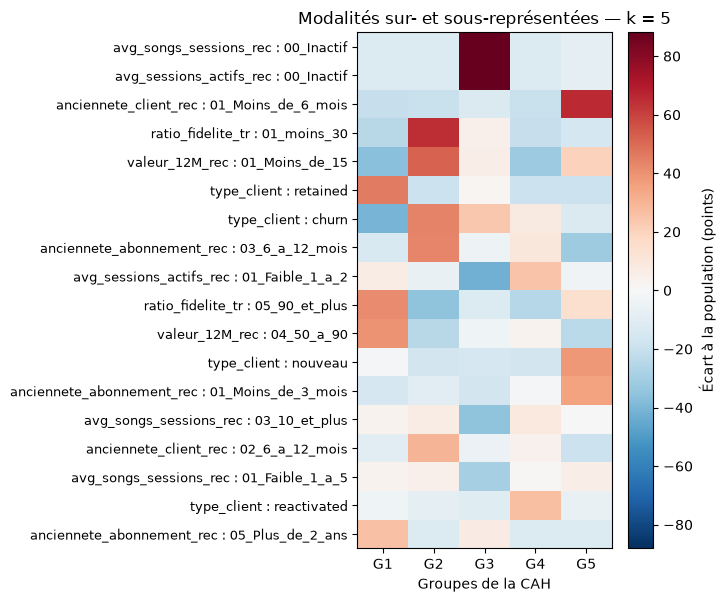


=== k = 6 : modalités caractéristiques ===


,Groupe,Variable,Modalité,Effectif modalité groupe,Part groupe (%),Part population (%),Écart (points)
0,1,type_client,retained,3307,64.41,18.80,45.61
1,1,ratio_fidelite_tr,05_90_et_plus,3987,77.66,36.10,41.55
2,1,valeur_12M_rec,04_50_a_90,3321,64.69,25.01,39.67
3,1,anciennete_abonnement_rec,05_Plus_de_2_ans,1952,38.02,11.86,26.16
4,1,valeur_12M_rec,05_Plus_de_90,1551,30.21,9.11,21.10
5,1,anciennete_client_rec,05_Plus_de_4_ans,1534,29.88,13.86,16.02
6,1,anciennete_abonnement_rec,04_1_a_2_ans,1486,28.94,13.33,15.61
7,1,anciennete_client_rec,04_2_a_4_ans,1566,30.50,18.27,12.23
8,2,ratio_fidelite_tr,01_moins_30,3831,92.27,27.30,64.96
9,2,valeur_12M_rec,01_Moins_de_15,3730,89.84,38.00,51.84


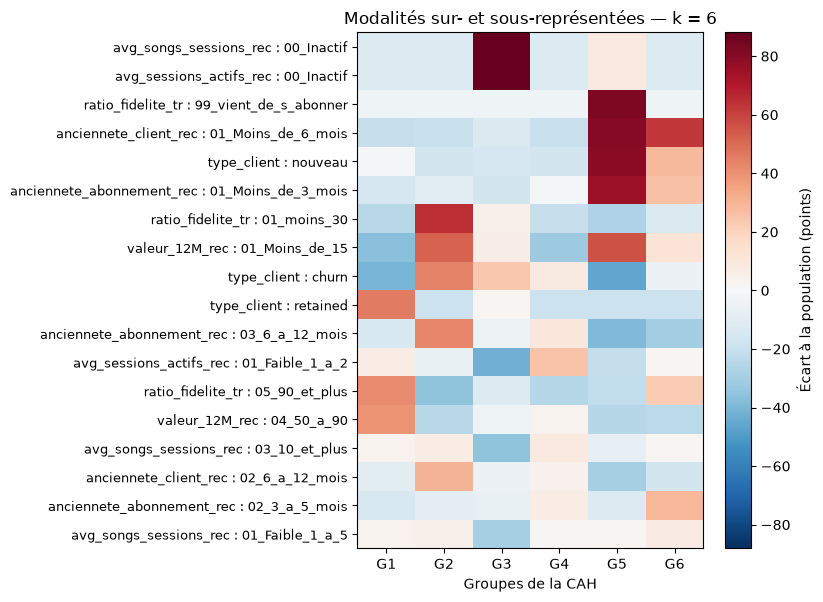

In [6]:
REPERTOIRE_SORTIE = RACINE / "resultats" / "cah" / "interpretation"
REPERTOIRE_SORTIE.mkdir(parents=True, exist_ok=True)

profils_par_k = {}
caracteristiques_par_k = {}
for k in VALEURS_K:
    if VARIABLES_QUALITATIVES:
        profils = profils_modalites(
            donnees_acm,
            partitions[f"groupe_k{k}"].to_numpy(),
            VARIABLES_QUALITATIVES,
        )
        profils_par_k[k] = profils
        caracteristiques = caracteristiques_principales(profils, nombre_par_groupe=8)
        caracteristiques_par_k[k] = caracteristiques
        profils.to_csv(REPERTOIRE_SORTIE / f"profils_k{k}_{MODE}_{NOMBRE_AXES_CAH}axes.csv", index=False)
        caracteristiques.to_csv(REPERTOIRE_SORTIE / f"caracteristiques_k{k}_{MODE}_{NOMBRE_AXES_CAH}axes.csv", index=False)
        print(f"\n=== k = {k} : modalités caractéristiques ===")
        display(caracteristiques[[
            "Groupe", "Variable", "Modalité", "Effectif modalité groupe",
            "Part groupe (%)", "Part population (%)", "Écart (points)"
        ]].round(2))
        afficher_carte_ecarts(profils, k, nombre_modalites=18)

## 6. Fiches métier par groupe

Les fiches ci-dessous présentent, pour chaque groupe et chaque partition, son effectif et les modalités **les plus surreprésentées et sous-représentées**, avec leurs fréquences dans le groupe et dans l'échantillon CAH. Les surreprésentations ne sont pas des causalités. Les intitulés métier ne sont **pas attribués automatiquement** : les tableaux permettent de les justifier.

Pour **k=6**, vérifier en priorité si le groupe le plus récent est réellement différent des autres au-delà de la simple ancienneté ; examiner les comportements de fidélité, de valeur et de consommation.

In [18]:
# 6. Fiches métier par groupe : calcul, noms et affichage séparé.
# Les intitulés sont provisoires et correspondent à l'essai de 20 000 clients.

profils_metier = {
    4: {
        1: ("Clients fidèles à forte valeur", "Fidélisation"),
        2: ("Clients à risque et profils intermédiaires", "Actions différenciées selon la fidélité"),
        3: ("Clients sans activité observée", "Réactivation de l'usage"),
        4: ("Clients récents", "Accompagnement des nouveaux clients"),
    },
    5: {
        1: ("Clients fidèles à forte valeur", "Fidélisation"),
        2: ("Clients en churn à faible fidélité", "Reconquête"),
        3: ("Clients sans activité observée", "Réactivation de l'usage"),
        4: ("Clients intermédiaires souvent réactivés", "Consolidation de la réactivation"),
        5: ("Clients récents", "Accompagnement des nouveaux clients"),
    },
    6: {
        1: ("Clients fidèles à forte valeur", "Fidélisation"),
        2: ("Clients en churn à faible fidélité", "Reconquête"),
        3: ("Clients sans activité observée", "Réactivation de l'usage"),
        4: ("Clients intermédiaires souvent réactivés", "Consolidation de la réactivation"),
        5: ("Tout nouveaux abonnés", "Onboarding initial"),
        6: ("Clients récents en fidélisation précoce", "Fidélisation précoce"),
    },
}

# Préparer les profils et enregistrer les tableaux détaillés.
fiches_par_k = {}
lignes_noms = []
for k in VALEURS_K:
    if k not in profils_metier:
        raise ValueError(f"Noms métier non définis pour k={k}.")

    fiches = fiches_groupes(
        profils_par_k[k], tailles, k, nombre_modalites=5
    )
    fiches_par_k[k] = fiches
    fiches.to_csv(
        REPERTOIRE_SORTIE / f"fiches_metier_k{k}_{MODE}_{NOMBRE_AXES_CAH}axes.csv",
        index=False,
    )

    groupes_observes = sorted(int(groupe) for groupe in partitions[f"groupe_k{k}"].unique())
    for groupe in groupes_observes:
        if groupe not in profils_metier[k]:
            raise ValueError(f"Nom métier manquant pour k={k}, groupe={groupe}.")
        nom, action = profils_metier[k][groupe]
        lignes_noms.append({
            "k": k,
            "Groupe": groupe,
            "Nom métier proposé": nom,
            "Action métier envisageable": action,
            "Statut": "Provisoire",
        })

noms_metier = pd.DataFrame(lignes_noms)
noms_metier.to_csv(REPERTOIRE_SORTIE / "noms_metier_proposes.csv", index=False)

# Afficher une table de synthèse, puis une fiche indépendante par groupe.
display(Markdown("### Noms métier proposés — synthèse"))
display(noms_metier)

for k in VALEURS_K:
    display(Markdown(f"## Partition en {k} groupes"))
    fiches = fiches_par_k[k]

    for groupe in sorted(int(groupe) for groupe in partitions[f"groupe_k{k}"].unique()):
        nom = profils_metier[k][groupe][0]
        fiche_groupe = fiches.loc[fiches["Groupe"] == groupe].copy()
        effectif = int((partitions[f"groupe_k{k}"] == groupe).sum())

        display(Markdown(f"### G{groupe} — {nom} ({effectif:,} clients)".replace(",", " ")))
        colonnes_redondantes = [
            colonne for colonne in ["k", "Groupe", "Effectif groupe", "Part groupe total (%)"]
            if colonne in fiche_groupe.columns
        ]
        display(fiche_groupe.drop(columns=colonnes_redondantes).reset_index(drop=True).round(2))

### Noms métier proposés — synthèse

,k,Groupe,Nom métier proposé,Action métier envisageable,Statut
0,4,1,Clients fidèles à forte valeur,Fidélisation,Provisoire
1,4,2,Clients à risque et profils intermédiaires,Actions différenciées selon la fidélité,Provisoire
2,4,3,Clients sans activité observée,Réactivation de l'usage,Provisoire
3,4,4,Clients récents,Accompagnement des nouveaux clients,Provisoire
4,5,1,Clients fidèles à forte valeur,Fidélisation,Provisoire
5,5,2,Clients en churn à faible fidélité,Reconquête,Provisoire
6,5,3,Clients sans activité observée,Réactivation de l'usage,Provisoire
7,5,4,Clients intermédiaires souvent réactivés,Consolidation de la réactivation,Provisoire
8,5,5,Clients récents,Accompagnement des nouveaux clients,Provisoire
9,6,1,Clients fidèles à forte valeur,Fidélisation,Provisoire


## Partition en 4 groupes

### G1 — Clients fidèles à forte valeur (5 134 clients)

,Type d'écart,Variable,Modalité,Fréquence dans le groupe (%),Fréquence totale (%),Écart (points)
0,Surreprésentée,type_client,retained,64.41,18.80,45.61
1,Surreprésentée,ratio_fidelite_tr,05_90_et_plus,77.66,36.10,41.55
2,Surreprésentée,valeur_12M_rec,04_50_a_90,64.69,25.01,39.67
3,Surreprésentée,anciennete_abonnement_rec,05_Plus_de_2_ans,38.02,11.86,26.16
4,Surreprésentée,valeur_12M_rec,05_Plus_de_90,30.21,9.11,21.10
5,Sous-représentée,type_client,churn,10.05,50.72,-40.67
6,Sous-représentée,valeur_12M_rec,01_Moins_de_15,1.09,38.00,-36.90
7,Sous-représentée,ratio_fidelite_tr,01_moins_30,2.63,27.30,-24.68
8,Sous-représentée,anciennete_client_rec,01_Moins_de_6_mois,0.00,20.04,-20.04
9,Sous-représentée,anciennete_abonnement_rec,01_Moins_de_3_mois,5.51,20.21,-14.69


### G2 — Clients à risque et profils intermédiaires (8 212 clients)

... (25 outputs left out)

### G5 — Tout nouveaux abonnés (843 clients)

,Type d'écart,Variable,Modalité,Fréquence dans le groupe (%),Fréquence totale (%),Écart (points)
0,Surreprésentée,ratio_fidelite_tr,99_vient_de_s_abonner,85.65,3.61,82.04
1,Surreprésentée,anciennete_client_rec,01_Moins_de_6_mois,100.00,20.04,79.96
2,Surreprésentée,type_client,nouveau,95.37,16.13,79.24
3,Surreprésentée,anciennete_abonnement_rec,01_Moins_de_3_mois,96.32,20.21,76.12
4,Surreprésentée,valeur_12M_rec,01_Moins_de_15,94.42,38.00,56.43
5,Sous-représentée,type_client,churn,4.63,50.72,-46.09
6,Sous-représentée,anciennete_abonnement_rec,03_6_a_12_mois,0.00,38.87,-38.87
7,Sous-représentée,anciennete_client_rec,02_6_a_12_mois,0.00,28.97,-28.97
8,Sous-représentée,ratio_fidelite_tr,01_moins_30,0.00,27.30,-27.30
9,Sous-représentée,valeur_12M_rec,04_50_a_90,0.00,25.01,-25.01


### G6 — Clients récents en fidélisation précoce (3 610 clients)

,Type d'écart,Variable,Modalité,Fréquence dans le groupe (%),Fréquence totale (%),Écart (points)
0,Surreprésentée,anciennete_client_rec,01_Moins_de_6_mois,82.66,20.04,62.61
1,Surreprésentée,anciennete_abonnement_rec,02_3_a_5_mois,44.76,15.74,29.03
2,Surreprésentée,type_client,nouveau,44.93,16.13,28.80
3,Surreprésentée,anciennete_abonnement_rec,01_Moins_de_3_mois,46.26,20.21,26.06
4,Surreprésentée,ratio_fidelite_tr,05_90_et_plus,58.67,36.10,22.57
5,Sous-représentée,anciennete_abonnement_rec,03_6_a_12_mois,8.98,38.87,-29.89
6,Sous-représentée,valeur_12M_rec,04_50_a_90,1.22,25.01,-23.80
7,Sous-représentée,type_client,retained,0.00,18.80,-18.80
8,Sous-représentée,anciennete_client_rec,03_1_a_2_ans,2.08,18.86,-16.78
9,Sous-représentée,contactable,non,23.35,40.03,-16.68


### Contrôle des variables quantitatives

Aucune variable quantitative supplémentaire n'est analysée : le périmètre est limité aux dix variables actives, toutes catégorielles, de l’ACM 3. `nb_abo_periode` n'est donc pas utilisé.

In [8]:
# Contrôle de l'absence de variables hors ACM
assert not VARIABLES_QUANTITATIVES
print("Aucune variable quantitative hors ACM n'est incluse dans l'interprétation.")

Aucune variable quantitative hors ACM n'est incluse dans l'interprétation.


## 7. Qu’est-ce qui change entre k = 4, 5 et 6 ?

Les tableaux de transition montrent quels groupes sont conservés ou divisés. Dans une CAH, le passage de *k* à *k + 1* doit diviser un groupe en deux, sans réaffecter les autres individus. Nous vérifions cette propriété et étudions les variables qui distinguent les deux groupes enfants.


=== Passage de k=4 à k=5 ===


,groupe_k4,groupe_k5,Effectif,Part du groupe source (%)
0,1,1,5134,100.00
1,2,2,4152,50.56
2,2,4,4060,49.44
3,3,3,2201,100.00
4,4,5,4453,100.00


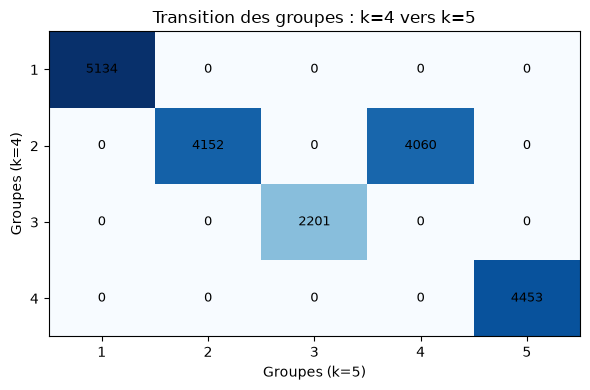

Modalités les plus différenciantes entre les groupes enfants :


,k parent,Groupe parent,k enfants,Groupe A,Groupe B,Variable,Modalité,Part A (%),Part B (%),Différence absolue (points)
0,4,2,5,2,4,ratio_fidelite_tr,01_moins_30,92.27,6.85,85.42
1,4,2,5,2,4,valeur_12M_rec,01_Moins_de_15,89.84,5.89,83.95
2,4,2,5,2,4,type_client,churn,94.41,58.82,35.59
3,4,2,5,2,4,type_client,reactivated,5.59,41.06,35.47
4,4,2,5,2,4,anciennete_abonnement_rec,03_6_a_12_mois,81.91,48.52,33.39
5,4,2,5,2,4,valeur_12M_rec,03_30_a_50,1.49,34.43,32.94
6,4,2,5,2,4,avg_sessions_actifs_rec,01_Faible_1_a_2,35.79,67.68,31.89
7,4,2,5,2,4,ratio_fidelite_tr,03_50a70,0.79,31.65,30.86
8,4,2,5,2,4,valeur_12M_rec,04_50_a_90,0.55,28.28,27.72
9,4,2,5,2,4,anciennete_client_rec,02_6_a_12_mois,59.22,32.93,26.29



=== Passage de k=5 à k=6 ===


,groupe_k5,groupe_k6,Effectif,Part du groupe source (%)
0,1,1,5134,100.00
1,2,2,4152,100.00
2,3,3,2201,100.00
3,4,4,4060,100.00
4,5,6,3610,81.07
5,5,5,843,18.93


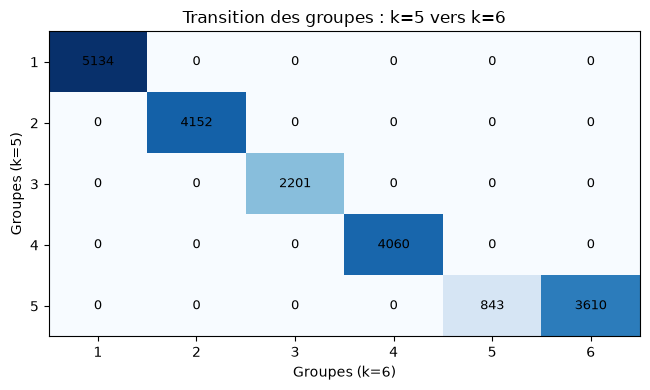

Modalités les plus différenciantes entre les groupes enfants :


,k parent,Groupe parent,k enfants,Groupe A,Groupe B,Variable,Modalité,Part A (%),Part B (%),Différence absolue (points)
0,5,5,6,5,6,ratio_fidelite_tr,99_vient_de_s_abonner,85.65,0.00,85.65
1,5,5,6,5,6,type_client,nouveau,95.37,44.93,50.44
2,5,5,6,5,6,anciennete_abonnement_rec,01_Moins_de_3_mois,96.32,46.26,50.06
3,5,5,6,5,6,ratio_fidelite_tr,05_90_et_plus,14.35,58.67,44.32
4,5,5,6,5,6,valeur_12M_rec,01_Moins_de_15,94.42,50.11,44.31
5,5,5,6,5,6,anciennete_abonnement_rec,02_3_a_5_mois,3.68,44.76,41.09
6,5,5,6,5,6,type_client,churn,4.63,45.65,41.02
7,5,5,6,5,6,valeur_12M_rec,02_15_a_30,2.49,25.93,23.44
8,5,5,6,5,6,avg_sessions_actifs_rec,01_Faible_1_a_2,21.35,44.04,22.69
9,5,5,6,5,6,avg_sessions_actifs_rec,00_Inactif,20.17,0.00,20.17


In [9]:
for k_source, k_cible in [(K_CENTRAL - 1, K_CENTRAL), (K_CENTRAL, K_CENTRAL + 1)]:
    transitions = transitions_groupes(partitions, k_source, k_cible)
    transitions.to_csv(
        REPERTOIRE_SORTIE / f"transitions_k{k_source}_k{k_cible}_{MODE}.csv", index=False
    )
    print(f"\n=== Passage de k={k_source} à k={k_cible} ===")
    display(transitions.round(2))
    afficher_transitions(transitions, k_source, k_cible)

    repartition_enfants = transitions.groupby(f"groupe_k{k_source}")[f"groupe_k{k_cible}"].nunique()
    if (repartition_enfants > 2).any() or (repartition_enfants == 2).sum() != 1:
        raise AssertionError("Les partitions ne correspondent pas à une scission hiérarchique unique.")

    if VARIABLES_QUALITATIVES:
        differences = differences_enfants(
            donnees_acm, partitions, k_source, k_cible,
            VARIABLES_QUALITATIVES, nombre_modalites=12,
        )
        print("Modalités les plus différenciantes entre les groupes enfants :")
        display(differences.round(2))
        differences.to_csv(
            REPERTOIRE_SORTIE / f"differences_k{k_source}_k{k_cible}_{MODE}.csv", index=False
        )

### Synthèse des deux scissions

Cette synthèse identifie **les groupes réellement divisés dans les données courantes** (sans supposer que les numéros ou effectifs sont constants entre les exécutions). Pour les **modalités qui différencient les enfants**, se reporter aux tableaux précédents.

Une scission peut être marquée descriptivement sans justifier une politique commerciale distincte. La pertinence du groupe de clients nouvellement abonnés doit être discutée en particulier.

In [10]:
scissions_resumees = pd.concat([
    resumer_scissions(transitions_groupes(partitions, depart, arrivee), depart, arrivee)
    for depart, arrivee in [(K_CENTRAL - 1, K_CENTRAL), (K_CENTRAL, K_CENTRAL + 1)]
], ignore_index=True)
display(scissions_resumees.round(2))
scissions_resumees.to_csv(REPERTOIRE_SORTIE / "synthese_scissions.csv", index=False)

,Passage,Groupe parent,Effectif parent,Groupe enfant,Effectif enfant,Part du parent (%)
0,4 → 5,2,8212,2,4152,50.56
1,4 → 5,2,8212,4,4060,49.44
2,5 → 6,5,4453,6,3610,81.07
3,5 → 6,5,4453,5,843,18.93


## 8. Comparaison des partitions et décision métier

Le tableau regroupe des faits calculés, sans imposer une valeur de *k*. Les silhouettes affichées correspondent **uniquement** à l’essai de 20 000 clients sur 4 axes ; elles sont fournies comme référence de l’exécution précédente. Une nouvelle expérience impose de vérifier et mettre à jour ces chiffres.

La décision définitive nécessite des profils exploitables **et** un contrôle de stabilité indépendant.

In [11]:
# Référence aux silhouettes exploratoires relevées dans le notebook 03 (20 000 individus, 4 axes).
# Ne pas réutiliser ces valeurs pour une autre expérience CAH.
SILHOUETTES_REFERENCE = {4: 0.350, 5: 0.336, 6: 0.354}
if len(partitions) != 20000 or NOMBRE_AXES_CAH != 4:
    raise ValueError("Les silhouettes de référence ne concernent que l'expérience 20 000 / 4 axes.")

bilan_metier = bilan_comparatif(tailles, scissions_resumees, SILHOUETTES_REFERENCE)
display(bilan_metier.round(3))
bilan_metier.to_csv(REPERTOIRE_SORTIE / "decision_metier_provisoire.csv", index=False)

print("Décision non arrêtée : comparer les fiches, les scissions et la stabilité.")

,k,Nombre de clients,Plus petit groupe,Part minimale (%),Silhouette exploratoire,Scission supplémentaire,Interprétabilité métier,Stabilité,Décision
0,4,20000,2201,11.005,0.350,Partition de référence,À argumenter à partir des fiches,À vérifier sur un autre échantillon,Non arrêtée
1,5,20000,2201,11.005,0.336,G2 → G2 (4152) + G4 (4060),À argumenter à partir des fiches,À vérifier sur un autre échantillon,Non arrêtée
2,6,20000,843,4.215,0.354,G5 → G6 (3610) + G5 (843),À argumenter à partir des fiches,À vérifier sur un autre échantillon,Non arrêtée


Décision non arrêtée : comparer les fiches, les scissions et la stabilité.


## 9. Conclusion provisoire et critères de validation

### 8.1. Démarche

La CAH de Ward a été effectuée sur **20 000 clients**, représentés par les quatre premiers axes de l'**ACM définitive (itération 3)**. L'ACM repose sur **dix variables actives et 42 modalités**, avec les regroupements définitifs. Les partitions étudiées sont **k = 4, 5 et 6**.

Les profils sont reconstruits à partir de ces **mêmes variables actives**, sans y ajouter de variable descriptive extérieure à l'ACM. Les cartes de chaleur montrent des écarts en **points de pourcentage**, et non des tests de significativité.

### 8.2. Ce que révèlent les scissions

- **De 4 à 5 groupes :** la scission principale sépare deux sous-populations d'effectif important. Les tableaux de différences permettent de vérifier si elles divergent en matière de fidélité, de valeur et de réactivation. Cette division est potentiellement très intéressante pour des actions commerciales distinctes.
- **De 5 à 6 groupes :** un sous-groupe de taille plus limitée apparaît. Dans l'exécution étudiée, l'analyse métier suggère un profil de clients très récents. Il faut déterminer si ce groupe mérite une politique d'onboarding spécifique ou si cette distinction traduit essentiellement une ancienneté réduite.

Les caractéristiques et effectifs exacts sont consignés dans les tableaux calculés ci-dessus ; **les intitulés métier restent provisoires**, tant qu'ils n'ont pas été vérifiés et validés.

### 8.3. Comparaison statistique

Sur l'expérience de **20 000 clients et quatre axes**, les silhouettes exploratoires relevées dans le notebook 03 sont : **0,350 (k=4), 0,336 (k=5), 0,354 (k=6)**. L'avantage de k=6 sur k=4 (**0,004**) est trop faible pour trancher à lui seul. Ces scores sont estimés sur un sous-échantillon.

La représentation sur deux axes est un **outil descriptif** : la CAH a été réalisée sur quatre axes, et des groupes peuvent se superposer sur un plan sans être identiques dans l'espace complet.

### 8.4. Décision provisoire

**Aucun nombre de groupes n'est définitivement retenu à cette étape.**

- **k=4 :** solution plus simple, à privilégier si les scissions n'apportent pas d'usage métier distinct.
- **k=5 :** choix particulièrement pertinent si la première scission confirme deux profils nécessitant des actions différentes.
- **k=6 :** justifié si le sous-groupe de clients récents possède une utilité opérationnelle propre **et** se révèle suffisamment stable.

La préférence finale doit résulter des **fiches descriptives**, de la lecture des **deux scissions** et de la **stabilité** des résultats sur une autre sélection de clients.

### 8.5. Ce qui reste à faire pour clôturer l'étape 1

1. Valider avec le métier les noms et actions possibles pour chaque segment.
2. Refaire une CAH avec une **autre sélection de 20 000 clients**, en conservant le modèle ACM, les quatre axes et Ward.
3. Comparer les profils et mesurer la concordance des partitions sur un **ensemble commun** après une méthode d'affectation évaluée (les simples numéros de groupe ne sont pas comparables).
4. Choisir une seule valeur de *k* et conserver une **partition de référence versionnée** avec ses identifiants, ses paramètres et ses étiquettes.

**Étape suivante :** entraîner un classifieur supervisé à reproduire les groupes retenus, puis l'appliquer aux clients restants et aux nouvelles observations, sans recalculer la CAH.